# Phishing Web Page Detection

**Goal:** classify a URL as **phishing** or **legitimate** using only the text of the URL, so a check is instant
and does not require visiting a possibly dangerous page.

**Data:** 11,429 URLs, exactly balanced between phishing and legitimate, from the
*Web page phishing detection* benchmark (Hannousse & Yahiouche, 2021; CC BY 4.0).

**Workflow:** extract features from each URL, explore them, train and compare models, evaluate the best one,
and look at which features matter most.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             classification_report, ConfusionMatrixDisplay)

from features import extract_features, features_from_urls

plt.rcParams["figure.figsize"] = (8, 4)

## 1. Load the data

In [2]:
data = pd.read_csv("data/urls.csv")
print(data.shape)
print(data["status"].value_counts())
data.sample(5, random_state=1)

(11429, 2)
status
legitimate    5715
phishing      5714
Name: count, dtype: int64


,url,status
11090,https://www.youtube.com/user/memorycardgametest,legitimate
9788,http://www.christkindlwirt.at/de/,legitimate
384,https://www.instagram.com/unicard.us,phishing
10032,http://www.icondigital.com/contact/,legitimate
3260,http://email.m-aut.ru/,phishing


## 2. Feature extraction

`features.py` turns every URL into 27 numbers, for example its length, number of dots and hyphens,
whether it uses an IP address instead of a domain name, how many subdomains it has, whether it contains words
like *login* or *verify*, and how random it looks (entropy). Example:

In [3]:
pd.Series(extract_features("http://paypal.com.secure-login.verify-account.xyz/webscr?cmd=update"))

url_length                    67.000000
hostname_length               42.000000
path_length                    7.000000
query_length                  10.000000
nb_dots                        4.000000
nb_hyphens                     2.000000
nb_at                          0.000000
nb_question                    1.000000
nb_equals                      1.000000
nb_slash                       3.000000
nb_percent                     0.000000
nb_digits                      0.000000
digit_ratio                    0.000000
nb_subdomains                  3.000000
has_www                        0.000000
is_https                       0.000000
has_ip                         0.000000
has_port                       0.000000
tld_length                     3.000000
domain_length                 14.000000
hyphen_in_domain               1.000000
double_slash_in_path           0.000000
nb_suspicious_words            6.000000
is_shortener                   0.000000
brand_in_subdomain_or_path     1.000000


In [4]:
X = features_from_urls(data["url"])
y = (data["status"] == "phishing").astype(int)        # 1 = phishing, 0 = legitimate
print(X.shape)
X.describe().T[["mean", "min", "max"]].round(2)

(11429, 27)


,mean,min,max
url_length,61.12,12.00,1641.00
hostname_length,21.09,4.00,214.00
path_length,23.15,0.00,602.00
query_length,9.10,0.00,1585.00
nb_dots,2.48,1.00,24.00
nb_hyphens,1.00,0.00,43.00
nb_at,0.02,0.00,4.00
nb_question,0.14,0.00,3.00
nb_equals,0.29,0.00,19.00
nb_slash,4.29,2.00,33.00


## 3. Explore: how do phishing URLs differ?

In [5]:
compare = X.groupby(y.map({0: "legitimate", 1: "phishing"})).mean().T
compare = compare.loc[["url_length", "nb_dots", "nb_hyphens", "nb_digits", "nb_subdomains",
                       "nb_suspicious_words", "has_ip", "has_www", "is_https"]]
compare.round(2)

status,legitimate,phishing
url_length,47.38,74.86
nb_dots,2.20,2.76
nb_hyphens,1.21,0.79
nb_digits,1.53,9.38
nb_subdomains,0.90,1.02
nb_suspicious_words,0.04,0.51
has_ip,0.00,0.02
has_www,0.67,0.21
is_https,0.44,0.33


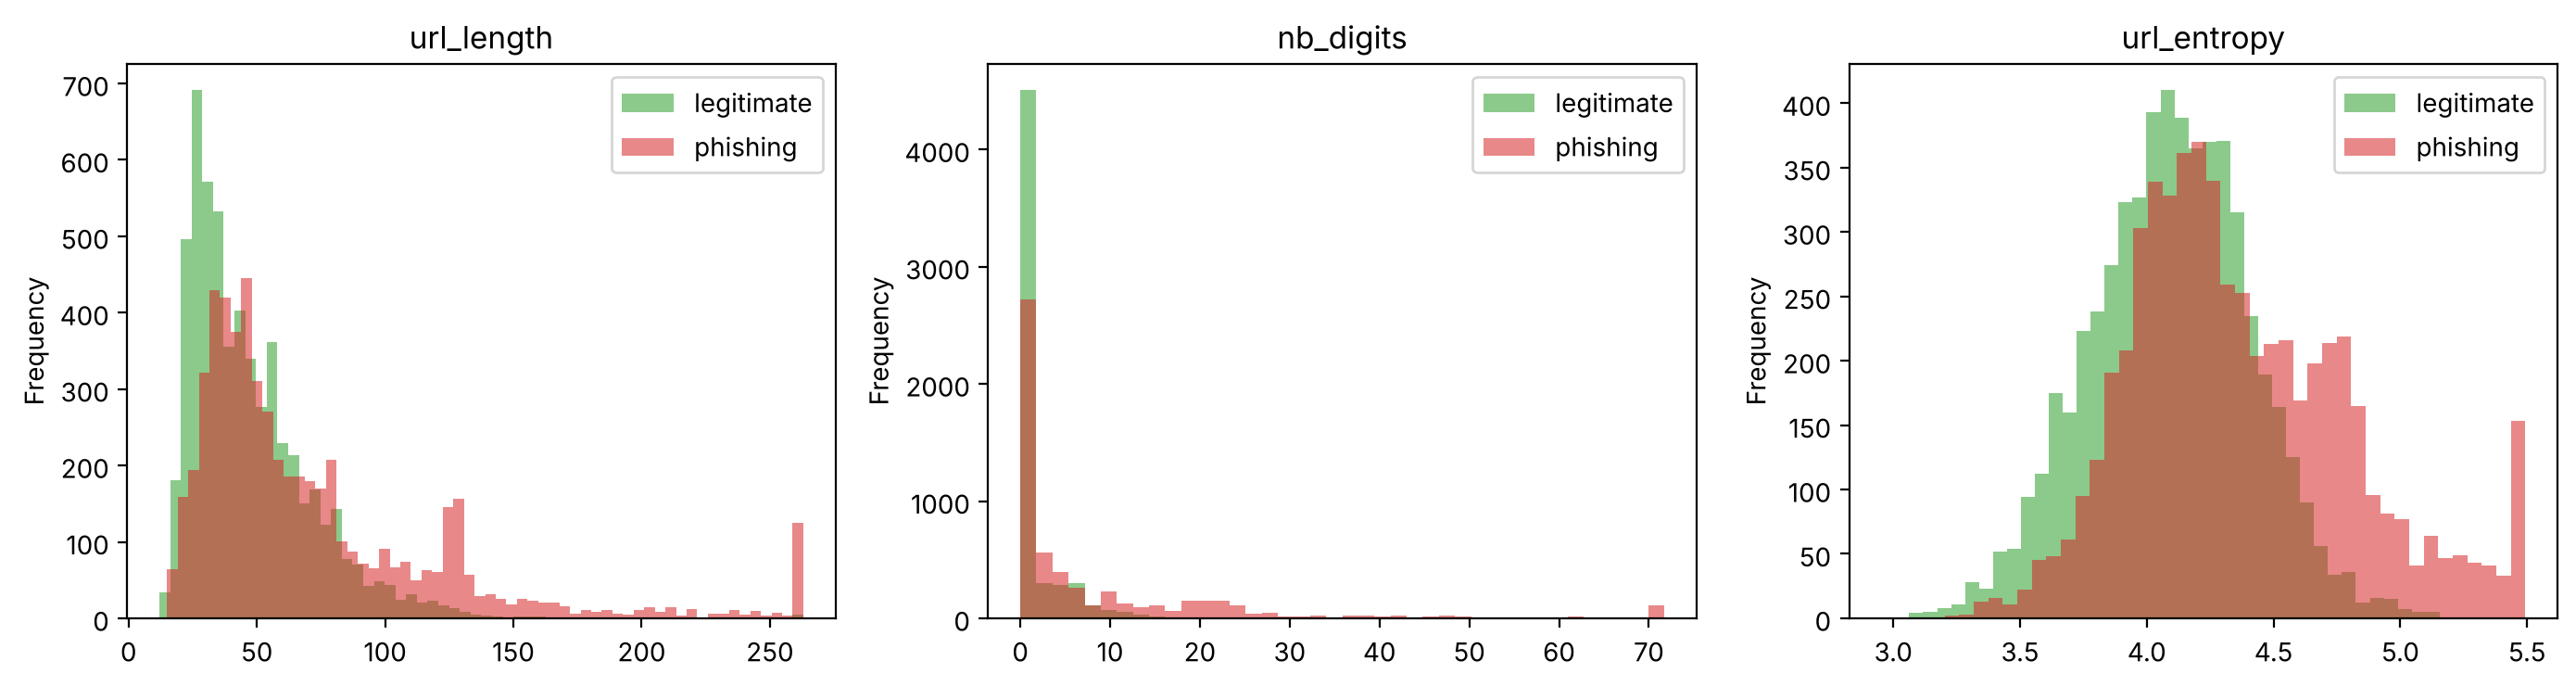

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, col, bins in zip(axes, ["url_length", "nb_digits", "url_entropy"], [60, 40, 40]):
    for label, name, color in [(0, "legitimate", "tab:green"), (1, "phishing", "tab:red")]:
        X.loc[y == label, col].clip(upper=X[col].quantile(0.99)).plot(
            kind="hist", bins=bins, alpha=0.55, ax=ax, label=name, color=color)
    ax.set_title(col); ax.legend()
plt.tight_layout(); plt.savefig("images/feature_distributions.png", dpi=120); plt.show()

Phishing URLs are on average **longer**, contain **more digits**, use **www** less often and more often
contain words like *login*, *secure* or *verify*. No single feature separates the classes perfectly,
which is why we combine them in a model.

## 4. Train and compare models

In [7]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

models = {
    "Logistic Regression (baseline)": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
    "Random Forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=2, n_jobs=-1, random_state=42),
    "Gradient Boosting": HistGradientBoostingClassifier(max_iter=300, learning_rate=0.08, random_state=42),
}

rows, fitted = [], {}
for name, model in models.items():
    cv_f1 = cross_val_score(model, X_train, y_train, cv=5, scoring="f1").mean()
    model.fit(X_train, y_train)
    pred, prob = model.predict(X_test), model.predict_proba(X_test)[:, 1]
    fitted[name] = model
    rows.append({"Model": name, "CV F1 (train)": cv_f1,
                 "Accuracy": accuracy_score(y_test, pred), "Precision": precision_score(y_test, pred),
                 "Recall": recall_score(y_test, pred), "F1": f1_score(y_test, pred),
                 "ROC-AUC": roc_auc_score(y_test, prob)})

results = pd.DataFrame(rows).set_index("Model").round(3)
results

,CV F1 (train),Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,,
Logistic Regression (baseline),0.826,0.853,0.864,0.837,0.851,0.934
Random Forest,0.902,0.916,0.915,0.916,0.916,0.972
Gradient Boosting,0.906,0.920,0.919,0.921,0.920,0.974


## 5. Evaluate the Random Forest

Random Forest was the model chosen in the original project. It is used in the app because it is accurate,
robust to features on different scales and easy to interpret through feature importance.

              precision    recall  f1-score   support

  legitimate       0.92      0.92      0.92      1143
    phishing       0.92      0.92      0.92      1143

    accuracy                           0.92      2286
   macro avg       0.92      0.92      0.92      2286
weighted avg       0.92      0.92      0.92      2286



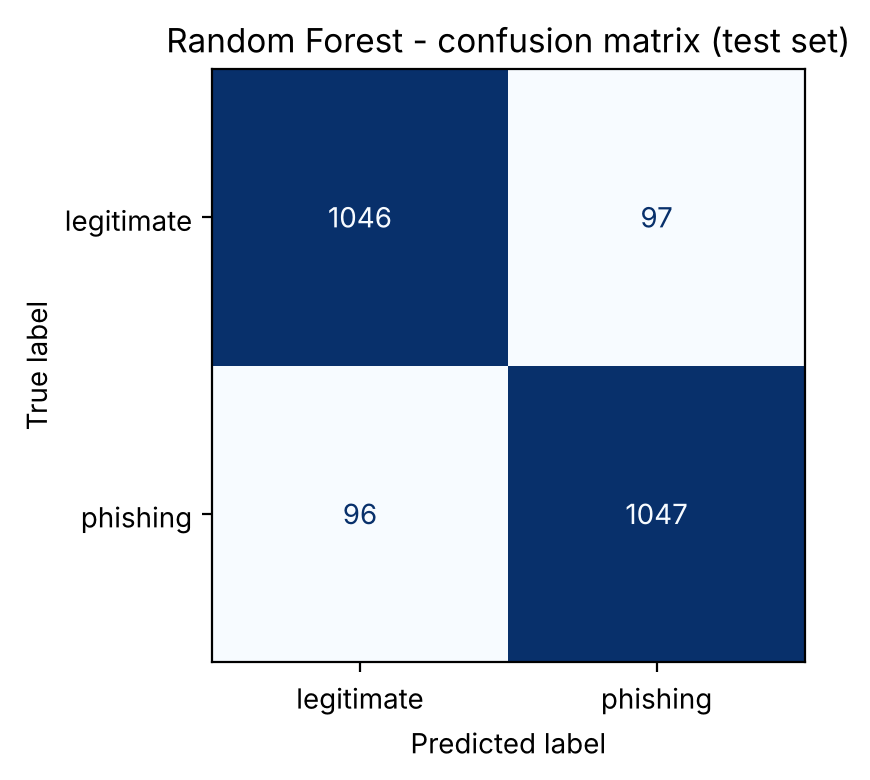

In [8]:
rf = fitted["Random Forest"]
pred = rf.predict(X_test)
print(classification_report(y_test, pred, target_names=["legitimate", "phishing"]))

ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=["legitimate", "phishing"],
                                        cmap="Blues", colorbar=False)
plt.title("Random Forest - confusion matrix (test set)")
plt.tight_layout(); plt.savefig("images/confusion_matrix.png", dpi=120); plt.show()

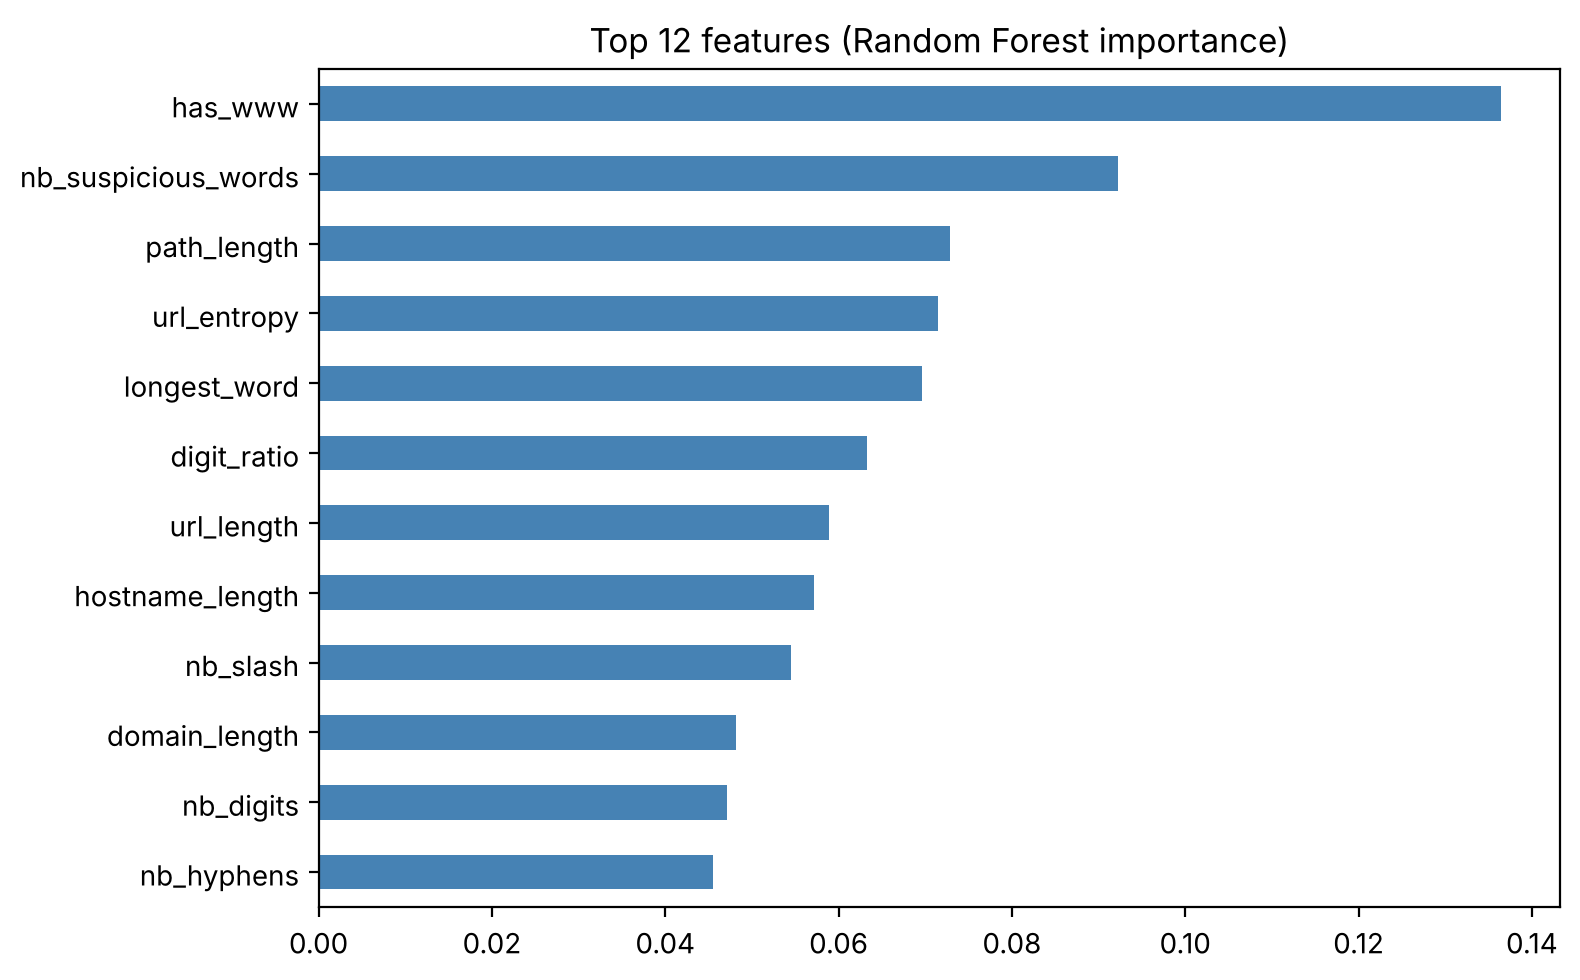

In [9]:
importance = pd.Series(rf.feature_importances_, index=X.columns).sort_values().tail(12)
importance.plot(kind="barh", color="steelblue", figsize=(8, 5))
plt.title("Top 12 features (Random Forest importance)")
plt.tight_layout(); plt.savefig("images/feature_importance.png", dpi=120); plt.show()

## 6. Try it on new URLs

In [10]:
examples = ["https://www.amazon.com",
            "https://github.com/explore",
            "http://amaz0n-update.info",
            "http://192.168.10.5/paypal/login.php",
            "http://secure-account-verify.bank-online-update.xyz/confirm?id=88231"]
probs = rf.predict_proba(features_from_urls(examples))[:, 1]
pd.DataFrame({"URL": examples, "Phishing probability": probs.round(2),
              "Prediction": np.where(probs >= 0.5, "phishing", "legitimate")})

,URL,Phishing probability,Prediction
0,https://www.amazon.com,0.09,legitimate
1,https://github.com/explore,0.65,phishing
2,http://amaz0n-update.info,0.78,phishing
3,http://192.168.10.5/paypal/login.php,0.96,phishing
4,http://secure-account-verify.bank-online-updat...,0.73,phishing


In [11]:
import os
os.makedirs("models", exist_ok=True)
joblib.dump(rf, "models/phishing_rf.joblib", compress=3)
print("Saved models/phishing_rf.joblib (used by the Streamlit app)")

Saved models/phishing_rf.joblib (used by the Streamlit app)


## 7. Conclusions

- Using only the URL text, the models separate phishing from legitimate URLs well; the exact scores are in the
  results table above.
- The most useful signals are whether the URL uses **www**, whether it contains **suspicious words** such as
  *login*, *verify* or *secure*, the **length of the path**, how **random** the URL looks (entropy) and the share
  of **digits**.
- The model is not perfect: in the examples above it flags `https://github.com/explore` as phishing, because the
  URL has no *www* and an unusual short structure. In a real product, a list of trusted domains would be checked first.
- URL-only detection is fast and safe, but it can miss phishing pages hosted on clean-looking URLs
  (for example on hacked legitimate sites).

**Possible next steps:** add page-content and domain-age (WHOIS) features, test on newer phishing URLs from
PhishTank/OpenPhish, and build a browser extension that checks links before they are opened.